# Joint RNA and ATAC analysis with bixverse

*Follows Signac's
[10x multiome vignette](https://stuartlab.org/signac/articles/pbmc_multiomic),
on the smaller 3k sibling of its data set.*

## Intro

10x multiome measures gene expression and chromatin accessibility in the
same nuclei. This vignette takes the unsorted 3k PBMC data set
(Cell Ranger ARC 2.0.0) through the steps of the Signac vignette: fragment
QC, multiplet calls, peak calling per cluster, TF-IDF and LSI, the weighted
nearest neighbour graph over both modalities, gene activity and label
transfer from RNA to ATAC.

ATAC lives next to the RNA in a `SingleCellsMultiModal`: a second v5 store
under `atac/` with peaks as features, TF-IDF as the norm and the genomic
coordinates in an interval index. Its cells are the RNA cells, in the same
order, so the RNA cell filter applies to both. Read the
[multi-modal vignette](multi_modal_single_cells.ipynb) first if you have not.

In [1]:
import tempfile
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed

## The data

`download_pbmc_multiome` fetches the files from the 10x data set page: the
filtered feature barcode matrix (RNA and Cell Ranger's peak counts in one
h5), the fragment file with its tabix index, Cell Ranger's peaks and the
GENCODE v32 annotation Cell Ranger ARC's GRCh38 reference was built from.

In [2]:
data_dir = bv.io.download_pbmc_multiome()
h5_path = data_dir / "pbmc_unsorted_3k_filtered_feature_bc_matrix.h5"
fragments = data_dir / "pbmc_unsorted_3k_atac_fragments.tsv.gz"
gtf = data_dir / "gencode.v32.primary_assembly.annotation.gtf.gz"

tempdir = tempfile.TemporaryDirectory()
exp_dir = Path(tempdir.name) / "pbmc_multiome"

## Loading

The RNA comes from the `Gene Expression` rows of the h5, the ATAC from its
`Peaks` rows. `add_atac_tenx` writes the peak store for every cell of the
RNA store, in its order.

In [3]:
bv.io.load_tenx_h5(exp_dir, h5_path)
mm = bv.SingleCellsMultiModal(exp_dir)
bv.atac.add_atac_tenx(mm, h5_path)
mm

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading 10x matrix structure (shape: 3_009 cells x 117_757 features)...
  Features after type filtering: 36_601 / 117_757
Quality pass - gene and cell statistics:
  Processed 100% of chunks (1/1)
  Genes passing filter: 16_556 / 36_601
Quality pass done: 105.57ms
  Cells passing filter: 2_956 / 3_009
Step 2/3: QC Results:
  Genes passing QC: 16_556 / 117_757
  Cells passing QC: 2_956 / 3_009
Step 3/3: Writing cells to CSR format...
  Processing 2_956 cells in batches of 8_192...
  Processed 2_956 / 2_956 cells
Converting the cell-based data into the gene-based format.
  Writing complete in 39.86ms


  Counted 4_723_733 non-zeros over 16_556 genes in 2.43ms; converting in 1 phase(s).
  Phase 1/1: genes 0-16556, scatter 11.57ms, compress + write 9.69ms
  Conversion into gene-friendly format done: 24.29ms


  Processing 2_956 cells in batches of 8_192...
  Processed 2_956 / 2_956 cells
  Writing complete in 52.25ms
  Counted 15_220_473 non-zeros over 81_156 genes in 7.26ms; converting in 1 phase(s).
  Phase 1/1: genes 0-81156, scatter 38.31ms, compress + write 40.96ms
  Conversion into gene-friendly format done: 87.83ms


SingleCellsMultiModal(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpxi1gx0e7/pbmc_multiome',
  cells=2956 (kept 2956), genes=16556,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
  adt=none, adt_pca=False, adt_knn=False, adt_graph=False,
  adt_embeddings=none,
  atac=AtacInfo(kind='peak', count_mode='insertion', tf_idf=False, lsi=False, lsi_dropped=[]), atac_embeddings=none, wnn=False
)

In [4]:
var = mm.var()
var.head()

gene_idx,gene_id,gene_name,feature_type,no_cells_exp
u32,str,str,str,i32
0,"""ENSG00000238009""","""AL627309.1""","""Gene Expression""",16
1,"""ENSG00000241860""","""AL627309.5""","""Gene Expression""",151
2,"""ENSG00000241599""","""AL627309.4""","""Gene Expression""",22
3,"""ENSG00000237491""","""LINC01409""","""Gene Expression""",158
4,"""ENSG00000228794""","""LINC01128""","""Gene Expression""",115


In [5]:
mm.var(modality="atac").head()

feature_idx,feature_id,chrom,start,end
u32,str,str,i64,i64
0,"""chr1:9782-10672""","""chr1""",9782,10672
1,"""chr1:180547-181446""","""chr1""",180547,181446
2,"""chr1:191121-191998""","""chr1""",191121,191998
3,"""chr1:267553-268447""","""chr1""",267553,268447
4,"""chr1:270906-271782""","""chr1""",270906,271782


## Quality control

Per cell from the fragment file: the number of fragments, the nucleosome
signal (mono- over nucleosome-free fragments), the TSS enrichment (Signac's
fast definition), the fraction on chrM and the fraction of fragments in
peaks. Mitochondrial RNA counts come from the RNA side as usual. Cell
Ranger ARC leaves chrM out of the fragment file, so the ATAC mito fraction
is zero throughout here.

In [6]:
atac_qc = bv.atac.atac_fragment_qc(mm, fragments, gtf)
atac_qc.head()

cell_idx,atac_n_fragments,atac_nucleosome_signal,atac_tss_enrichment,atac_mito_fraction,atac_frip
u32,i64,f64,f64,f64,f64
0,8887,0.706014,6.103767,0.0,0.637617
1,11975,0.670251,5.919949,0.0,0.633612
2,3162,0.485326,8.097166,0.0,0.747312
3,8284,0.669105,5.788354,0.0,0.651195
4,11090,0.750823,5.289348,0.0,0.616141


In [7]:
symbol_col = "gene_name"
mito = var.filter(pl.col(symbol_col).str.contains("^MT-"))["gene_id"].to_list()
bv.qc.gene_set_proportions(mm, {"MT": mito}, streaming=False, verbose=False)

### Multiplets

Multiome nuclei carry two copies of each chromosome, so a locus covered by
more than two of a cell's fragments points at a second nucleus. AMULET counts
those loci per cell and tests them against a Poisson background. It needs no
clustering and no RNA. With a repeat list (`restrict_beds`) the calls are
cleaner; without one, loci in repeats inflate the counts of every cell alike.

In [8]:
amulet = bv.atac.amulet(mm, fragments)
print(f"{amulet['amulet_multiplet'].sum()} of {amulet.height} cells called multiplets")

113 of 2956 cells called multiplets


### Thresholds

Signac's thresholds for the 10k sibling on the ATAC side: `1800 < nCount <
1e5` peak counts, nucleosome signal under 2, TSS enrichment over 1. On the
RNA side we flag MAD outliers on library size and genes, and cells above
3 MADs of mitochondrial share.

In [9]:
obs = mm.obs(
    cols=[
        "cell_idx",
        "lib_size",
        "nnz",
        "MT",
        "atac_lib_size",
        "atac_nucleosome_signal",
        "atac_tss_enrichment",
        "atac_frip",
        "amulet_multiplet",
    ]
)
obs.describe()

statistic,cell_idx,lib_size,nnz,MT,atac_lib_size,atac_nucleosome_signal,atac_tss_enrichment,atac_frip,amulet_multiplet
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",2956.0,2956.0,2956.0,2956.0,2956.0,2956.0,2956.0,2956.0,2956.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1477.5,3220.143437,1598.015223,0.114833,12060.634641,0.650115,5.889341,0.632367,0.038227
"""std""",853.468023,1742.789674,564.342442,0.077015,7715.911753,0.17593,1.338179,0.079258,null
"""min""",0.0,251.0,102.0,0.000581,40.0,0.287037,0.056487,0.098785,0.0
"""25%""",739.0,2176.0,1241.0,0.06904,6518.0,0.541445,5.271987,0.603654,null
"""50%""",1478.0,2779.0,1497.0,0.119007,12645.0,0.631909,5.66608,0.634876,null
"""75%""",2216.0,3868.0,1882.0,0.153489,16149.0,0.722527,6.224761,0.671308,null
"""max""",2955.0,33378.0,5416.0,0.806593,143069.0,2.339512,30.16983,0.835033,1.0


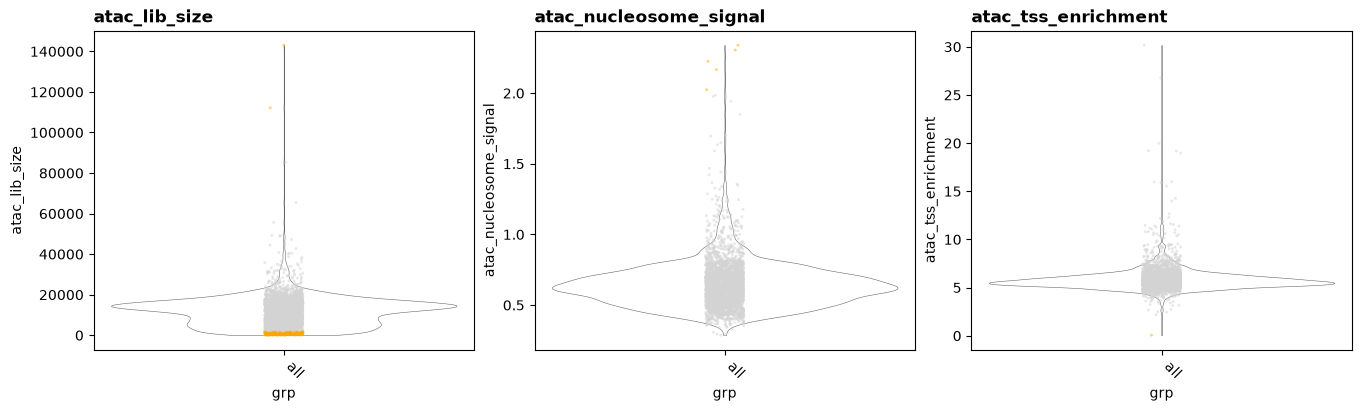

In [10]:
atac_metrics = {
    "atac_lib_size": obs["atac_lib_size"].to_numpy(),
    "atac_nucleosome_signal": obs["atac_nucleosome_signal"].to_numpy(),
    "atac_tss_enrichment": obs["atac_tss_enrichment"].to_numpy(),
}
atac_calls = bv.qc.run_cell_qc_fixed(
    atac_metrics,
    obs["cell_idx"].to_numpy(),
    {
        "atac_lib_size": {"lower": 1800, "upper": 100_000},
        "atac_nucleosome_signal": {"upper": 2},
        "atac_tss_enrichment": {"lower": 1},
    },
)
bv.pl.violin_plot(atac_calls)
plt.show()

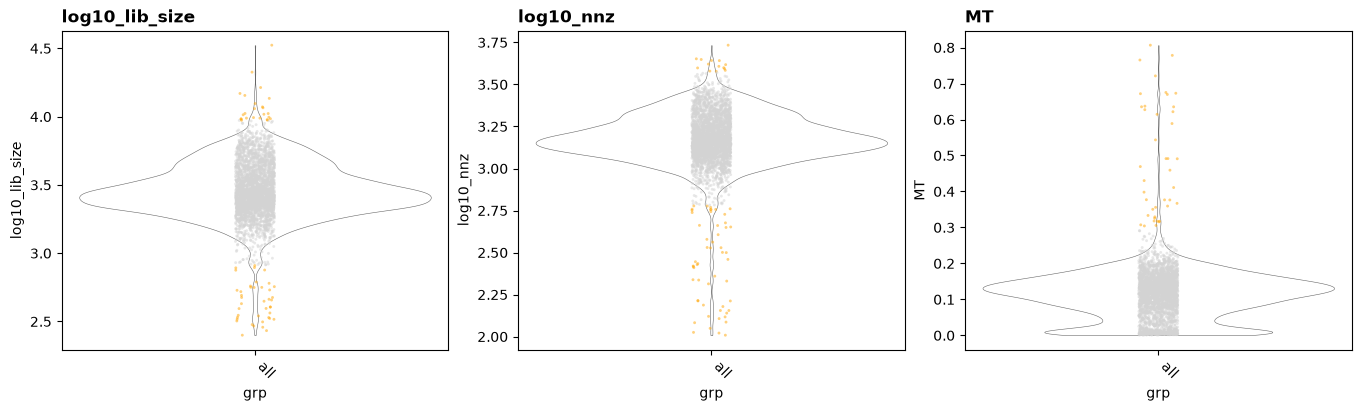

In [11]:
rna_metrics = {
    "log10_lib_size": np.log10(obs["lib_size"].to_numpy()),
    "log10_nnz": np.log10(obs["nnz"].to_numpy()),
    "MT": obs["MT"].to_numpy(),
}
directions: dict[str, Literal["twosided", "below", "above"]] = {
    "log10_lib_size": "twosided",
    "log10_nnz": "twosided",
    "MT": "above",
}
rna_calls = bv.qc.run_cell_qc(
    rna_metrics, obs["cell_idx"].to_numpy(), directions=directions, threshold=3.0
)
bv.pl.violin_plot(rna_calls)
plt.show()

In [12]:
multiplet = obs["amulet_multiplet"].to_numpy()
drop = atac_calls.combined | rna_calls.combined | multiplet
print(
    f"ATAC fails {atac_calls.combined.sum()}, RNA fails {rna_calls.combined.sum()}, "
    f"multiplets {multiplet.sum()}, dropped {drop.sum()} of {drop.size}"
)
mm.set_cells_to_keep(obs["cell_idx"].to_numpy()[~drop])

ATAC fails 216, RNA fails 89, multiplets 113, dropped 380 of 2956


## RNA

The usual: highly variable genes, PCA, kNN, Leiden. These clusters are what
the peaks get called on below.

HVG (VST): 16_556 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 6.32ms
HVG (VST): Fitted Loess in 723.54µs
HVG (VST): Standardised variance in 347.33µs (85 gene(s) re-read for the clip)
HVG (VST): Total run time -> 7.43ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 5.73ms
Sparse PCA: finished the data preparations in 1.02ms


Sparse PCA: finished calculations in 224.52ms
Sparse PCA: total run time -> 231.41ms
Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 11.99ms
Generated KmKnn index: 12.13ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 4.01ms
Queried KmKnn index: 4.03ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 5.93ms


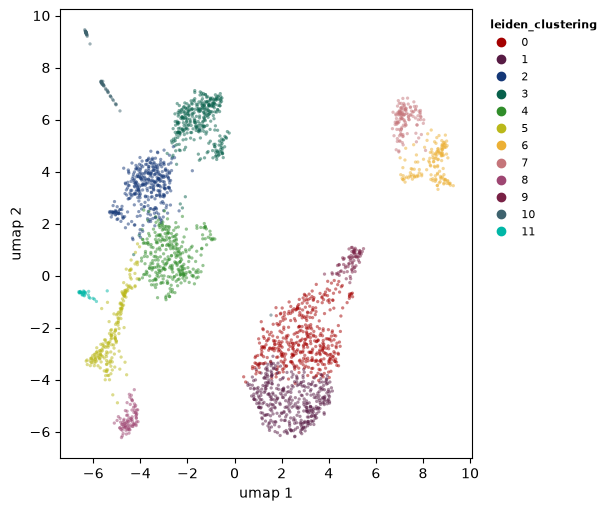

In [13]:
bv.pp.find_hvg(mm, hvg_no=2000)
bv.pp.calculate_pca(mm, no_pcs=50)
bv.graph.find_neighbours(mm, no_embd_to_use=30)
bv.graph.find_clusters(mm, res=0.8)
bv.embed.umap(mm, no_embd_to_use=30)
bv.pl.embedding_plot(mm, "umap", "leiden_clustering", discrete=True, point_size=0.5)
plt.show()

## Peaks

Cell Ranger calls peaks on all cells pooled, which under-calls rare
populations. As in the Signac vignette we call them per cluster with a native
port of MACS3 `callpeak` (Signac's settings: `--nomodel --extsize 200
--shift -100`), merge the per cluster peaks and count the fragments against
the merged set. The new store replaces the Cell Ranger one.

In [14]:
cr_peaks = mm.var(modality="atac").height
peaks = bv.atac.call_peaks(mm, fragments, group_by="leiden_clustering")
print(f"Cell Ranger peaks: {cr_peaks}, merged per-cluster peaks: {peaks.height}")
peaks.head()

Cell Ranger peaks: 81156, merged per-cluster peaks: 125094


chrom,start,end,peak_called_in
str,u32,u32,str
"""GL000194.1""",28241,28529,"""2,3,7"""
"""GL000194.1""",55974,56192,"""6"""
"""GL000194.1""",101245,101524,"""5,6,8"""
"""GL000194.1""",114816,115137,"""0,1,3,4,7,9,10"""
"""GL000195.1""",24051,24251,"""1"""


In [15]:
peaks = peaks.filter(pl.col("chrom").str.contains(r"^chr[0-9XY]+$"))
bv.atac.add_atac_fragments(mm, fragments, peaks=peaks)
mm.var(modality="atac").head()

  Counted 15_705_268 non-zeros over 125_061 genes in 8.34ms; converting in 1 phase(s).
  Phase 1/1: genes 0-125061, scatter 42.17ms, compress + write 52.05ms
  Conversion into gene-friendly format done: 104.84ms


feature_idx,feature_id,chrom,start,end
u32,str,str,i64,i64
0,"""chr1:10057-10379""","""chr1""",10057,10379
1,"""chr1:180681-181048""","""chr1""",180681,181048
2,"""chr1:191409-191609""","""chr1""",191409,191609
3,"""chr1:267865-268136""","""chr1""",267865,268136
4,"""chr1:271209-271549""","""chr1""",271209,271549


## TF-IDF and LSI

TF-IDF over the kept cells (Signac method 1), the most accessible peaks, then
a truncated SVD. The first component tracks sequencing depth; we look before
dropping it.

In [16]:
bv.atac.run_tfidf(mm)
top = bv.atac.find_top_features(mm, min_cutoff="q5")
print(f"{top.size} top peaks")
bv.atac.calculate_lsi(mm, n_comp=50)
bv.atac.get_lsi_depth_cor(mm).head(5)

120423 top peaks


component,depth_cor,dropped
i64,f64,bool
1,0.971331,true
2,-0.076289,false
3,0.191935,false
4,-0.058824,false
5,0.374858,false


Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 11.87ms
Generated KmKnn index: 12.11ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 5.39ms
Queried KmKnn index: 5.41ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 5.72ms


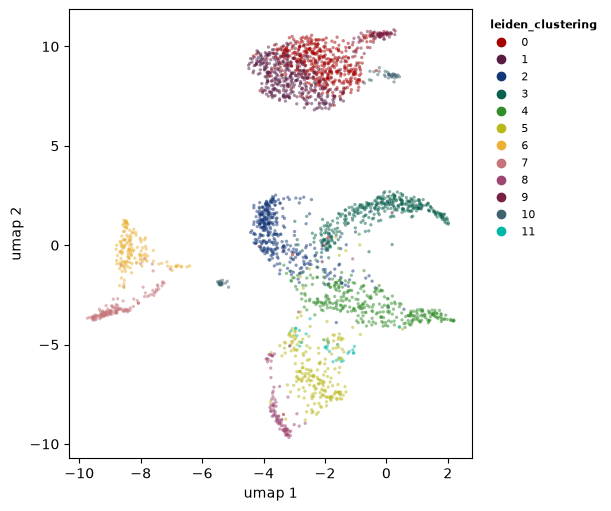

In [17]:
bv.graph.find_neighbours(mm, embd_to_use="lsi", modality="atac")
bv.embed.umap(mm, embd_to_use="lsi", modality="atac")
bv.pl.embedding_plot(
    mm, "umap", "leiden_clustering", discrete=True, embd_modality="atac", point_size=0.5
)
plt.show()

The RNA clusters should stay together on the ATAC UMAP: the two modalities
come from the same nuclei.

## Weighted nearest neighbours

WNN fuses the RNA PCA and the ATAC LSI per cell, weighting each by how well
it predicts the cell's neighbourhood.

Running WNN graph generation.


Running the kNN generation for modality 1 with 200 neighbours.
Running the kNN generation for modality 2 with 200 neighbours.
Built the Snn { similarity: Jaccard, prune: 0.0, rescue: false } graph: 7.92ms
Built the Snn { similarity: Jaccard, prune: 0.0, rescue: false } graph: 5.96ms
WNN: per-modality SNN built in 14.31ms
WNN: modality weights in 3.36ms
WNN: graph constructed in 5.61ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 7.46ms


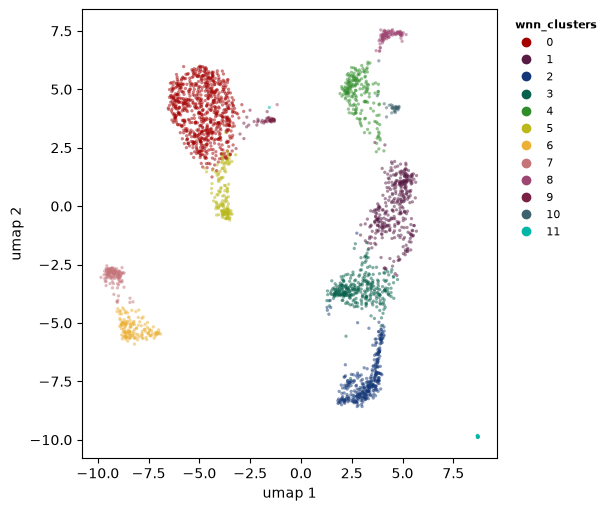

In [18]:
bv.mm.generate_wnn_graph(
    mm,
    modality_2="atac",
    embd_to_use_2="lsi",
    no_embd_to_use_1=50,
)
bv.graph.find_clusters(mm, modality="wnn", name="wnn_clusters", res=0.8)
bv.embed.umap(mm, modality="wnn")
bv.pl.embedding_plot(
    mm,
    "umap",
    "wnn_clusters",
    discrete=True,
    embd_modality="wnn",
    point_size=0.5,
)
plt.show()

In [19]:
weights = bv.mm.get_wnn_weights(mm)
weights.head()

cell_id,weight_modality_1,weight_modality_2
str,f64,f64
"""AAACAGCCAACAGGTG-1""",0.566951,0.433049
"""AAACATGCAACAACAA-1""",0.616319,0.383681
"""AAACCAACACAGCCTG-1""",0.362178,0.637822
"""AAACCAACAGCAAGAT-1""",0.600295,0.399705
"""AAACCAACATTGCGAC-1""",0.491891,0.508109


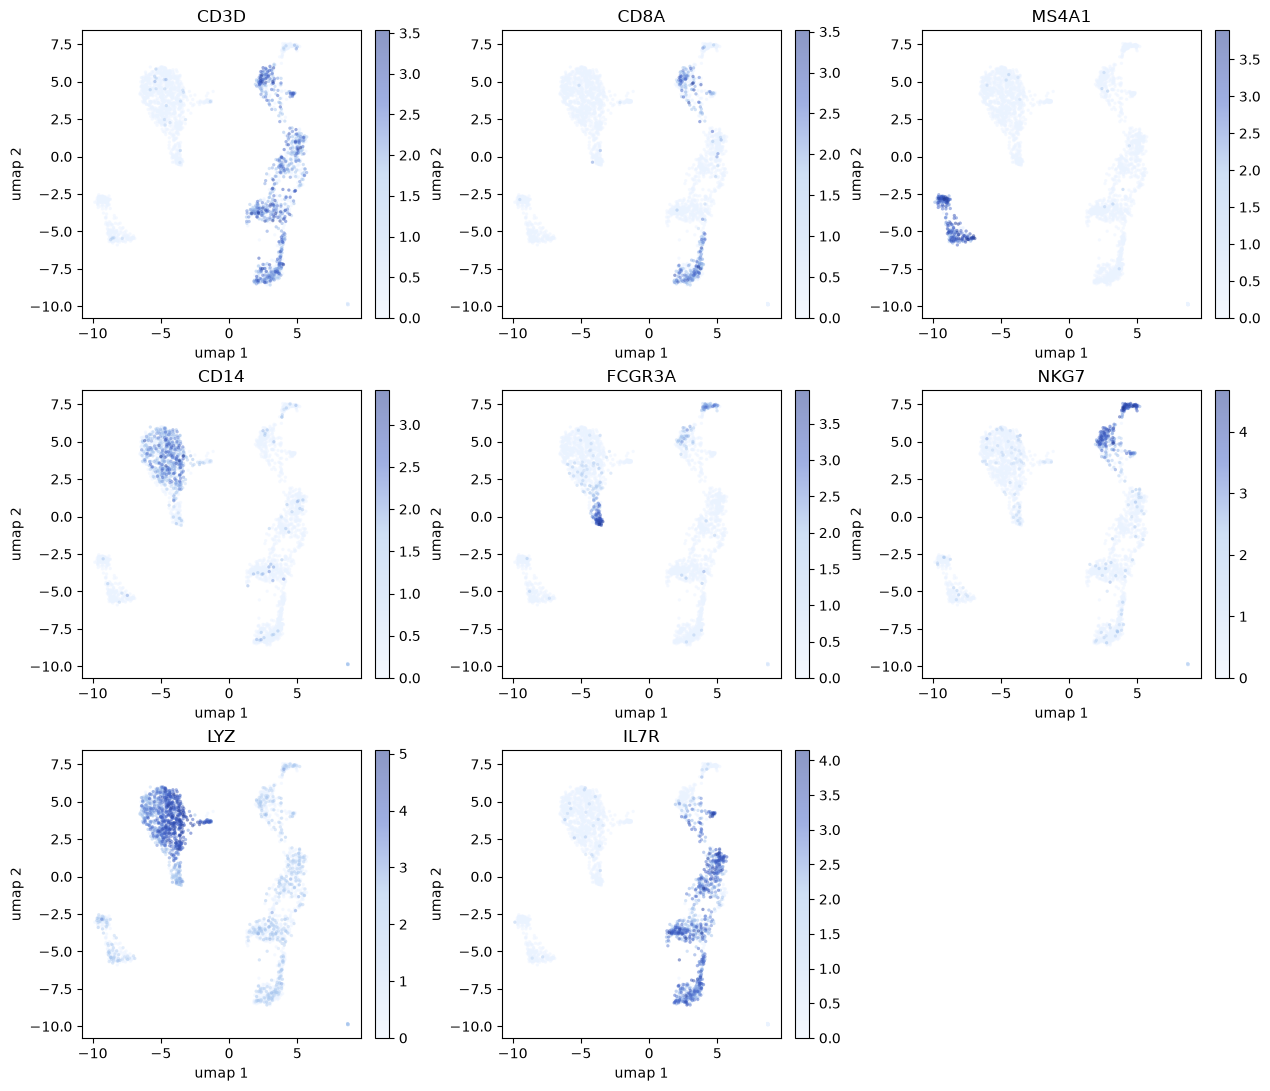

In [20]:
symbol_to_id = dict(zip(var[symbol_col], var["gene_id"], strict=False))
markers = ["CD3D", "CD8A", "MS4A1", "CD14", "FCGR3A", "NKG7", "LYZ", "IL7R"]
bv.pl.feature_plot(
    mm,
    [symbol_to_id[g] for g in markers],
    "umap",
    feature_labels={symbol_to_id[g]: g for g in markers},
    embd_modality="wnn",
    point_size=0.5,
)
plt.show()

## Gene activity and label transfer

Gene activity counts fragments over gene body plus 2 kb upstream (Signac's
`GeneActivity`) into a gene by cell store of its own. It is the shared
feature space for moving labels from an RNA reference onto ATAC cells. With
paired data we know the answer: the RNA clusters of the same nuclei. Transfer
them through gene activity and the ATAC LSI and count how many come back.

In [21]:
ga = bv.atac.gene_activity(mm, fragments, gtf)
ga.var().head()

  Counted 15_581_236 non-zeros over 19_675 genes in 5.98ms; converting in 1 phase(s).
  Phase 1/1: genes 0-19675, scatter 38.66ms, compress + write 16.01ms
  Conversion into gene-friendly format done: 61.30ms


gene_idx,gene_id,gene_name,chrom,start,end,no_cells_exp
u32,str,str,str,i64,i64,i32
0,"""ENSG00000186092""","""OR4F5""","""chr1""",63418,71585,3
1,"""ENSG00000284733""","""OR4F29""","""chr1""",450702,453697,0
2,"""ENSG00000284662""","""OR4F16""","""chr1""",685678,688673,0
3,"""ENSG00000187634""","""SAMD11""","""chr1""",921927,944581,815
4,"""ENSG00000188976""","""NOC2L""","""chr1""",944202,961309,1130


In [22]:
transfer = bv.annotate.transfer_labels_seurat(
    mm,
    ga,
    "leiden_clustering",
    mm.atac_cache.embeddings["lsi"],
)
truth = mm.obs(cols=["leiden_clustering"], filtered=True)["leiden_clustering"]
predicted = transfer["predicted_leiden_clustering"].cast(pl.String)
agree = (predicted == truth.cast(pl.String)).mean()
print(f"transferred label equals the RNA cluster for {agree:.1%} of cells")

transferred label equals the RNA cluster for 82.7% of cells


## Differential accessibility

The marker functions take `modality="atac"` and test peaks instead of
genes: here every WNN cluster against the rest. On ATAC the default is
Signac's recommended test, a logistic regression per peak with the
library size as covariate (`group ~ peak + nCount` against
`group ~ nCount`), so a cluster with deeper cells does not light up every
peak. `method="wilcox"` gets you the Wilcoxon on the TF-IDF layer instead.

Don't read these p-values as inference. Every cell counts as a replicate,
so with a few hundred cells per cluster they go astronomically small with
either test; use them to rank peaks. With replicates,
`bv.de.pseudobulk_dge(..., modality="atac")` runs edgeR on summed peak
counts per sample, which is the test to trust.

In [23]:
da = bv.de.find_all_markers(mm, "wnn_clusters", modality="atac", verbose=0)
da.filter(pl.col("fdr") < 0.05).group_by("grp").len().sort("grp")

grp,len
i32,u32
0,11238
1,8898
2,9661
3,9075
4,7067
…,…
7,7587
8,5085
9,6564


In [24]:
da.filter(pl.col("fdr") < 0.05).sort("lfc", descending=True).head(10)

grp,gene_id,lfc,prop1,prop2,z_scores,p_values,fdr
i32,str,f64,f64,f64,f64,f64,f64
11,"""chr7:98642114-98642362""",1.979545,0.4,0.000392,9.304002,6.7629e-21,1.2204e-16
11,"""chr17:73561095-73561482""",1.96873,0.4,0.002352,8.928001,2.1689e-19,1.9569e-15
11,"""chr10:33715301-33715777""",1.926497,0.4,0.000784,9.333007,5.1455e-21,1.2204e-16
11,"""chr20:43711245-43711660""",1.853279,0.36,0.002352,8.456146,1.3818e-17,8.3118e-14
11,"""chr12:6188947-6189355""",1.769473,0.4,0.006664,8.193441,1.2693e-16,5.0901e-13
11,"""chr10:47441900-47442248""",1.756526,0.32,0.0,8.710571,1.5117e-18,1.0912e-14
11,"""chr7:98641583-98642000""",1.75159,0.4,0.003136,8.155129,1.7440e-16,6.2944e-13
11,"""chr3:53190375-53190965""",1.725381,0.4,0.006272,8.095359,2.8548e-16,6.8688e-13
11,"""chr14:89773085-89773520""",1.716058,0.36,0.002744,8.099043,2.7697e-16,6.8688e-13
